# Przetwarzanie języka naturalnego

Dziś zajmiemy się analizą tekstu na przykładzie krótkich recenzji filmowych. Zaczniemy od prostych reprezentacji tekstu (Bag-of-Words, TF-IDF), potem użyjemy gotowych wektorów zdań (sentence embeddings) do wyszukiwania podobnych recenzji i jako cech dla klasyfikatora, a następnie dostroimy model BERT do klasyfikacji sentymentu za pomocą biblioteki Hugging Face `transformers`. Wytrenowany model zapiszemy, użyjemy go na nowych recenzjach i przygotujemy prosty raport, w którym niepewne przypadki trafiają do sprawdzenia przez człowieka. W zadaniach dodatkowych zajrzymy do wnętrza transformera: zaimplementujemy mechanizm atencji (attention) i własną pętlę generowania tekstu.

## Konfiguracja środowiska

Możesz korzystać ze środowiska lokalnego z menedżerem pakietów [uv](https://docs.astral.sh/uv/) lub z [Google Colab](https://colab.research.google.com/). Wszystko zostało przetestowane z użyciem `uv` - jeżeli w trakcie pracy instalujesz biblioteki ręcznie przez `pip`, to coś może się zepsuć lub nie działać z powodu niekompatybilnych wersji.

W tym laboratorium dostrajamy model BERT, który ma ok. 110 mln parametrów. Na karcie graficznej trening trwa kilka minut, a na CPU kilkanaście do kilkudziesięciu, więc warto mieć GPU. Jeżeli nie masz komputera z kartą NVIDIA lub procesorem Apple z serii M, skorzystaj z Google Colab.

### Środowisko lokalne

Konfiguracja wygląda tak samo, jak w poprzednich laboratoriach:
1. Instalacja uv [zgodnie z dokumentacją](https://docs.astral.sh/uv/getting-started/installation/) (jeżeli nie masz go jeszcze zainstalowanego)
2. Stworzenie środowiska wirtualnego: `uv venv`
3. Aktywacja środowiska wirtualnego: zgodnie z komendą wypisaną przez `uv venv`, np. `source .venv/bin/activate` na Linuxie/macOS/WSL
4. Zainstalowanie zależności z pliku `uv.lock`: `uv sync`
5. Uruchomienie Jupyter Notebooka: `uv run jupyter notebook` (samo `jupyter notebook` też zadziała w aktywowanym venv'ie)

Na Linuxie i Windowsie instalowana jest wersja PyTorcha z obsługą kart graficznych NVIDIA (CUDA 13.0), która wymaga sterownika NVIDIA w wersji 580 lub nowszej. Działa ona również na komputerach bez karty NVIDIA - wtedy obliczenia wykonywane są na CPU. Na macOS PyTorch korzysta z akceleracji na procesorach Apple z serii M (MPS).

### Google Colab

Wybierz środowisko wykonawcze z GPU (Środowisko wykonawcze -> Zmień typ środowiska wykonawczego -> np. T4 GPU), a następnie prześlij do katalogu `/content` plik `requirements.txt`. PyTorch jest w Colabie zainstalowany domyślnie, a pozostałe zależności zainstalujesz, wykonując `!pip install -r requirements.txt` w osobnej komórce notebooka.

Zbiór danych i modele zostaną pobrane automatycznie z [Hugging Face Hub](https://huggingface.co/) przy pierwszym uruchomieniu (łącznie ok. 600 MB) i zapisane w pamięci podręcznej, więc kolejne uruchomienia nie wymagają już pobierania.

In [ ]:
# uncomment and run if using Google Colab
# !pip install -r requirements.txt

In [ ]:
import random

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print(DEVICE)

pd.set_option("display.max_colwidth", None)
datasets.disable_progress_bars()

## Dane

Korzystamy ze zbioru [Rotten Tomatoes](https://huggingface.co/datasets/cornell-movie-review-data/rotten_tomatoes), czyli krótkich, zwykle jednozdaniowych recenzji filmowych po angielsku. Każda recenzja ma etykietę `0` (negatywna) lub `1` (pozytywna). Pobierzemy go z Hugging Face Hub biblioteką `datasets`.

Zbiór ma gotowy podział na część treningową, walidacyjną i testową. Kilka recenzji powtarza się jednak między podziałami (czasem różnią się tylko wielkością liter lub spacjami), a kopia recenzji testowej w zbiorze treningowym zawyżyłaby wynik. Dlatego usuwamy takie duplikaty. Żeby trening na CPU nie trwał zbyt długo, losujemy też zrównoważone podzbiory: 2000 recenzji treningowych, 400 walidacyjnych i 600 testowych. Zbiór walidacyjny posłuży do wyboru modelu i jego ustawień, a testowy tylko do końcowej oceny.

In [ ]:
from datasets import load_dataset

rotten_tomatoes = load_dataset("cornell-movie-review-data/rotten_tomatoes")


def normalize(texts: pd.Series) -> pd.Series:
    return texts.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()


seen = set()
splits = {}
for split, size in [("train", 2000), ("validation", 400), ("test", 600)]:
    df = rotten_tomatoes[split].to_pandas()
    normalized = normalize(df.text)
    # drop duplicates inside the split and texts that already appeared in earlier splits
    df = df[~normalized.duplicated() & ~normalized.isin(seen)]
    seen.update(normalized)
    # balanced subset (size // 2 reviews from each class) in random order
    df = df.groupby("label").sample(n=size // 2, random_state=SEED)
    splits[split] = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

train, valid, test = splits["train"], splits["validation"], splits["test"]
print(f"train: {len(train)}, validation: {len(valid)}, test: {len(test)}")
display(train.head(6))

### Zadanie 1 (1 punkt)

Zanim zaczniemy trenować modele, warto przyjrzeć się danym. Oblicz udział procentowy każdej klasy w zbiorze treningowym (`class_pct`, obiekt `pd.Series`) i długość każdej recenzji w słowach (`word_counts`, wystarczy podział po białych znakach). Narysuj histogram długości recenzji i wyświetl najkrótszą oraz najdłuższą recenzję.

In [ ]:
# your_code

In [ ]:
assert isinstance(class_pct, pd.Series) and np.isclose(class_pct.sum(), 100)
assert word_counts.shape == (len(train),) and (word_counts > 0).all()

## Bag-of-Words i TF-IDF

Modele uczenia maszynowego operują na liczbach, więc tekst trzeba najpierw zamienić na wektor. Najprostszy sposób to **worek słów (Bag-of-Words, BoW)**. Budujemy słownik ze wszystkich słów w zbiorze treningowym, a każdy tekst opisujemy wektorem, którego współrzędne mówią, ile razy dane słowo wystąpiło w tekście. Kolejność słów jest przy tym tracona, więc „good, not bad” i „bad, not good” dostaną identyczne wektory. Częściowo można temu zaradzić, dodając do słownika **n-gramy**, czyli sekwencje kolejnych słów, np. bigram „not good”.

W scikit-learn robi to `CountVectorizer`. W tabeli poniżej wiersze to teksty, a kolumny to słowa ze słownika.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

lexical_examples = ["good movie good acting", "bad movie", "good acting"]
bow_demo = CountVectorizer()
bow_counts = bow_demo.fit_transform(lexical_examples)
pd.DataFrame(
    bow_counts.toarray(),
    columns=bow_demo.get_feature_names_out(),
    index=lexical_examples,
)

Nie wszystkie słowa są równie przydatne. Słowo „movie” pojawia się w ogromnej części recenzji filmowych, więc niewiele mówi o konkretnej recenzji. **TF-IDF (term frequency - inverse document frequency)** mnoży liczbę wystąpień słowa w tekście (TF) przez wagę, która jest tym mniejsza, w im większej liczbie dokumentów słowo występuje (IDF). `TfidfVectorizer` dodatkowo normalizuje każdy wiersz do długości 1. Porównaj wartości z poprzednią tabelą.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_demo = TfidfVectorizer()
tfidf_weights = tfidf_demo.fit_transform(lexical_examples)
pd.DataFrame(
    tfidf_weights.toarray(),
    columns=tfidf_demo.get_feature_names_out(),
    index=lexical_examples,
).round(3)

Na takich wektorach możemy wytrenować dowolny klasyfikator, np. regresję logistyczną. Wektoryzator i klasyfikator łączymy w jeden `Pipeline`. Dzięki temu słownik i wagi IDF są dopasowywane tylko na zbiorze treningowym, a na walidacji i teście są jedynie stosowane.

Wyniki wszystkich modeli będziemy zbierać we wspólnej tabeli walidacyjnej. Funkcja `register` dodaje do niej model, a dokładniej dwie funkcje: zwracającą predykcje dla listy tekstów i zwracającą prawdopodobieństwo klasy pozytywnej, które przyda się później. Oprócz dokładności (accuracy) liczymy **macro-F1**, czyli średnią z miar F1 obliczonych osobno dla każdej klasy. Punktem odniesienia jest klasyfikator, który zawsze przewiduje najczęstszą klasę.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline


def scores(y_true, y_pred) -> dict[str, float]:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


validation_rows = []
registry = {}  # model name -> function: list of texts -> predicted labels
probability_registry = {}  # model name -> function: list of texts -> probability of class 1


def register(name, predict_fn, proba_fn) -> pd.DataFrame:
    # running a cell again replaces the model's previous result instead of duplicating it
    validation_rows[:] = [row for row in validation_rows if row["model"] != name]
    validation_rows.append(
        {"model": name, **scores(valid.label, predict_fn(valid.text.tolist()))}
    )
    registry[name] = predict_fn
    probability_registry[name] = proba_fn
    return pd.DataFrame(validation_rows)


dummy = DummyClassifier(strategy="most_frequent").fit(train.text, train.label)
register("Dummy", dummy.predict, lambda texts: dummy.predict_proba(texts)[:, 1])

### Zadanie 2 (1 punkt)

Zbuduj funkcją `make_pipeline` dwa modele: `bow_clf` z `CountVectorizer` i `tfidf_clf` z `TfidfVectorizer`. W obu wektoryzatorach użyj unigramów i bigramów, pomiń n-gramy występujące w mniej niż 2 recenzjach i ogranicz słownik do 12000 najczęstszych n-gramów (`ngram_range=(1, 2), min_df=2, max_features=12000`). Jako klasyfikatora użyj `LogisticRegression(max_iter=500, random_state=SEED)`. Wytrenuj oba modele na zbiorze treningowym i zarejestruj je funkcją `register` pod nazwami `"BoW"` i `"TF-IDF"`.

In [ ]:
# your_code

pd.DataFrame(validation_rows)

In [ ]:
assert {"BoW", "TF-IDF"} <= set(registry)
assert isinstance(bow_clf[0], CountVectorizer) and isinstance(
    tfidf_clf[0], TfidfVectorizer
)
for model in [bow_clf, tfidf_clf]:
    assert model[0].ngram_range == (1, 2)
    assert model.predict(valid.text.iloc[:3]).shape == (3,)

## Wektory zdań (sentence embeddings)

Wektory BoW są bardzo długie (jedna współrzędna na każde słowo ze słownika) i nic nie wiedzą o znaczeniu słów. „Great” i „excellent” to dla nich zupełnie różne kolumny. **Embedding** to krótszy wektor liczb rzeczywistych, wyuczony przez sieć neuronową tak, żeby teksty o podobnym znaczeniu miały podobne wektory. Użyjemy biblioteki [Sentence Transformers](https://www.sbert.net/) i modelu [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), który zamienia całe zdanie na wektor 384 liczb. Metoda `encode` przyjmuje listę tekstów i zwraca macierz z jednym wierszem na tekst.

Podobieństwo dwóch wektorów mierzymy zwykle **podobieństwem cosinusowym (cosine similarity)**. Jeżeli wektory są znormalizowane do długości 1 (`normalize_embeddings=True`), jest ono po prostu iloczynem skalarnym. Zobaczmy, jak wygląda dla kilku zdań. Zwróć uwagę na parę zdań o świetnym i okropnym filmie. Mają przeciwny wydźwięk, ale dotyczą tego samego tematu, więc ich wektory wcale nie są od siebie dalekie.

In [ ]:
from sentence_transformers import SentenceTransformer

sentence_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2", device=DEVICE
)
theory_texts = [
    "The film was excellent.",
    "A wonderful movie.",
    "The film was terrible.",
    "The delivery arrived late.",
]
theory_vectors = sentence_model.encode(theory_texts, normalize_embeddings=True)
print("Embeddings shape:", theory_vectors.shape)

sim = theory_vectors @ theory_vectors.T
fig, ax = plt.subplots(figsize=(7, 4))
image = ax.imshow(sim, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(4), theory_texts, rotation=25, ha="right")
ax.set_yticks(range(4), theory_texts)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="cosine similarity")
plt.tight_layout()
plt.show()

Policzmy od razu wektory wszystkich recenzji treningowych i walidacyjnych, przydadzą się w kolejnym zadaniu.

In [ ]:
def encode_texts(texts) -> np.ndarray:
    return sentence_model.encode(list(texts), batch_size=64, normalize_embeddings=True)


train_vectors = encode_texts(train.text)
valid_vectors = encode_texts(valid.text)
print(train_vectors.shape, valid_vectors.shape)

### Zadanie 3 (1 punkt)

Wektory zdań pozwalają wyszukiwać teksty o podobnej treści (**semantic search**). Znajdź 5 recenzji treningowych najbardziej podobnych do zapytania `"The acting was excellent but the story was boring."`. Zakoduj zapytanie funkcją `encode_texts`, policz jego podobieństwa do wszystkich wektorów `train_vectors` (`similarities`) i wybierz indeksy 5 największych (`top_indices`). Wyświetl te recenzje razem z etykietami i podobieństwami.

Wektory zdań mogą też być cechami dla klasyfikatora. Wytrenuj na `train_vectors` regresję logistyczną `probe` z tymi samymi parametrami co w zadaniu 2 i zarejestruj ją jako `"Sentence + LR"`. Model zdań pozostaje przy tym zamrożony, uczymy tylko wagi regresji. Takie podejście nazywa się **linear probing**, bo sprawdzamy, czy z gotowej reprezentacji da się liniowo odczytać interesującą nas informację. Pamiętaj, że funkcje przekazywane do `register` dostają listę tekstów, a nie wektory.

Czy znalezione recenzje dotyczą tego samego co zapytanie? Czy mają ten sam wydźwięk? Jak linear probing wypadł w porównaniu z modelami z zadania 2?

In [ ]:
query = "The acting was excellent but the story was boring."
# your_code

In [ ]:
assert similarities.shape == (len(train),)
assert len(set(top_indices)) == 5
assert np.allclose(similarities[top_indices], np.sort(similarities)[::-1][:5])
assert "Sentence + LR" in registry
assert probe.coef_.shape == (1, train_vectors.shape[1])

// skomentuj tutaj

Wektory zdań przydają się też do szukania tematów bez żadnych etykiet. Pogrupujmy recenzje treningowe algorytmem KMeans w 5 klastrów i wypiszmy dla każdego 3 recenzje najbliższe środkowi klastra. Numer klastra nie ma nic wspólnego z sentymentem, a nazwę tematu można nadać dopiero po przeczytaniu przykładów. Grupy bywają też niespójne, więc to raczej narzędzie do wstępnego przeglądu tekstów niż gotowa odpowiedź.

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, random_state=SEED, n_init=10)
cluster_labels = kmeans.fit_predict(train_vectors)
representative_rows = []
for cluster_id in range(5):
    indices = np.flatnonzero(cluster_labels == cluster_id)
    distances = np.linalg.norm(
        train_vectors[indices] - kmeans.cluster_centers_[cluster_id], axis=1
    )
    for index in indices[np.argsort(distances)[:3]]:
        representative_rows.append(
            {"cluster": cluster_id, "text": train.text.iloc[index]}
        )
pd.DataFrame(representative_rows)

## Tokenizacja i dane dla BERT-a

Teraz dostroimy do naszego zadania model [BERT](https://arxiv.org/abs/1810.04805) (Bidirectional Encoder Representations from Transformers). To transformer typu enkoder (encoder), wstępnie wytrenowany na dużym zbiorze angielskich tekstów. Dla każdego tokenu zwraca wektor, który zależy od kontekstu z obu stron. Słowo „bank” dostanie więc inną reprezentację w zdaniu o rzece, a inną w zdaniu o pieniądzach.

BERT nie operuje na słowach, tylko na **tokenach**, czyli słowach lub ich fragmentach ze stałego słownika. Rzadkie słowo zostaje podzielone na kilka częstszych fragmentów, co widać w przykładzie poniżej (`##` oznacza kontynuację poprzedniego tokenu). Tokenizator zgodny z modelem wczytuje `AutoTokenizer`. Zamienia on tekst na listę identyfikatorów tokenów (`input_ids`) i dodaje tokeny specjalne: `[CLS]` na początku i `[SEP]` na końcu. Teksty w jednym batchu muszą mieć tę samą długość, więc krótsze uzupełnia się tokenem `[PAD]` (**padding**), a `attention_mask` mówi modelowi, które pozycje są prawdziwymi tokenami. Zbyt długie teksty obcina się (**truncation**) do ustalonego limitu.

Wczytajmy tokenizator i sprawdźmy, ile recenzji przekracza limit 64 tokenów. Dane zamienimy też na obiekty `Dataset` z biblioteki `datasets`, z którymi współpracuje `Trainer`.

In [ ]:
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, DataCollatorWithPadding

BERT_NAME = "google-bert/bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
print(bert_tokenizer.tokenize("An unbelievably dull screenplay."))

MAX_LENGTH = 64
lengths = np.array(
    [len(ids) for ids in bert_tokenizer(train.text.tolist())["input_ids"]]
)
print(f"Longest training review: {lengths.max()} tokens")
print(f"Reviews longer than {MAX_LENGTH} tokens: {(lengths > MAX_LENGTH).mean():.1%}")

collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)
raw_datasets = DatasetDict(
    {
        name: Dataset.from_pandas(df[["text", "label"]], preserve_index=False)
        for name, df in [("train", train), ("validation", valid), ("test", test)]
    }
)
raw_datasets

### Zadanie 4 (1 punkt)

Uzupełnij funkcję `tokenize_batch`, która tokenizuje listę tekstów `batch["text"]` tokenizatorem `bert_tokenizer` z obcinaniem do `MAX_LENGTH` tokenów (`truncation=True, max_length=MAX_LENGTH`). Nie dodawaj paddingu. Zrobi to dopiero `DataCollatorWithPadding` przy tworzeniu batcha, dzięki czemu każdy batch jest dopełniany tylko do długości swojego najdłuższego tekstu. Zastosuj funkcję do wszystkich podzbiorów metodą `raw_datasets.map(tokenize_batch, batched=True, remove_columns=["text"])` i zapisz wynik w `tokenized`. Kolumna `label` ma zostać w danych.

Na koniec wypisz tokeny pierwszej recenzji treningowej (`bert_tokenizer.convert_ids_to_tokens`).

In [ ]:
def tokenize_batch(batch):
    # your_code


# your_code

In [ ]:
example_batch = collator([tokenized["train"][i] for i in range(3)])
assert (
    "label" in tokenized["train"].column_names
    and "text" not in tokenized["train"].column_names
)
assert example_batch["input_ids"].shape == example_batch["attention_mask"].shape
assert example_batch["input_ids"].shape[1] <= MAX_LENGTH
assert example_batch["labels"].shape == (3,)
assert tokenized["train"][0]["input_ids"][0] == bert_tokenizer.cls_token_id
assert tokenized["train"][0]["input_ids"][-1] == bert_tokenizer.sep_token_id

## Fine-tuning BERT-a

Klasa `AutoModelForSequenceClassification` wczytuje wstępnie wytrenowanego BERT-a i dokłada na jego wyjściu **głowę klasyfikacyjną (classification head)**. To warstwa liniowa, która z wektora tokenu `[CLS]` liczy dwa logity, po jednym dla każdej klasy. Wagi enkodera pochodzą z pretreningu, ale głowa jest nowa i ma losowe wagi. Dlatego biblioteka wypisze ostrzeżenie, że wagi `classifier` nie zostały wczytane z checkpointu. Tak ma być.

**Fine-tuning** polega na dalszym trenowaniu całego modelu na naszych oznaczonych danych, z małą stałą uczącą. W odróżnieniu od linear probingu z zadania 3 zmieniają się nie tylko wagi głowy, ale też wszystkie wagi enkodera. Różnicę pokazuje schemat poniżej. BERT-base ma ok. 110 mln parametrów, więc trening jest znacznie droższy niż w przypadku regresji logistycznej.

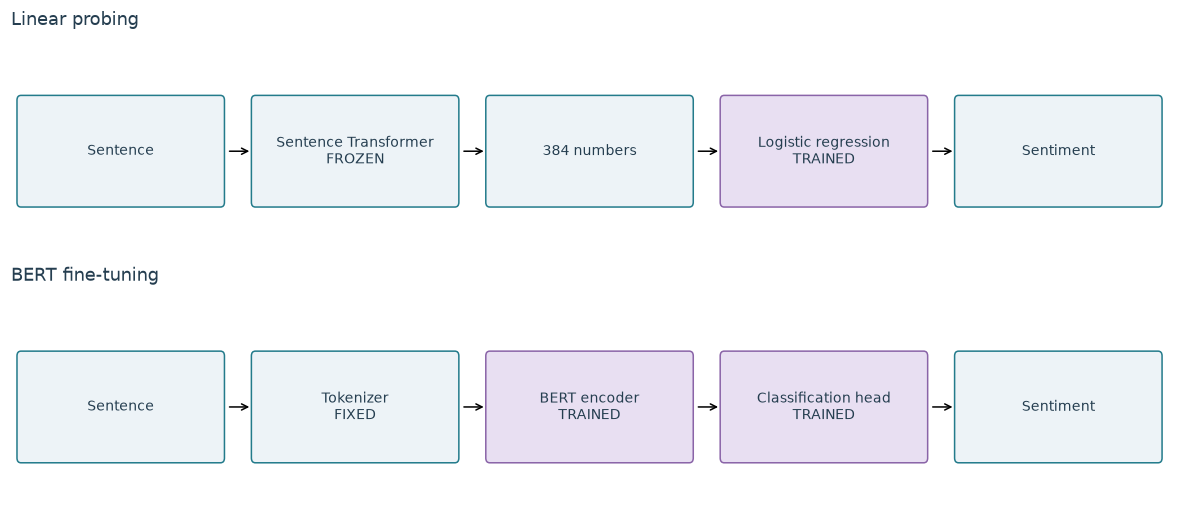

In [ ]:
from transformers import (
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    set_seed,
)

set_seed(SEED)
id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {label: index for index, label in id2label.items()}
bert_classifier = AutoModelForSequenceClassification.from_pretrained(
    BERT_NAME, num_labels=2, id2label=id2label, label2id=label2id
)
n_params = sum(p.numel() for p in bert_classifier.parameters())
print(f"Parameters: {n_params / 1e6:.1f} M")
print(bert_classifier.classifier)

# copy of one encoder weight matrix, to check later that fine-tuning changed the encoder too
encoder_before = (
    bert_classifier.bert.encoder.layer[-1].output.dense.weight.detach().clone()
)

EPOCHS = 4
BATCH_SIZE = 16

Pętli uczącej nie będziemy pisać ręcznie. Biblioteka `transformers` udostępnia klasę [`Trainer`](https://huggingface.co/docs/transformers/main_classes/trainer), która sama tworzy batche, liczy gradienty, wykonuje kroki optymalizatora (domyślnie AdamW ze stałą uczącą malejącą liniowo do zera), co jakiś czas ocenia model na zbiorze walidacyjnym i zapisuje checkpointy. Wszystkie ustawienia przekazujemy w obiekcie [`TrainingArguments`](https://huggingface.co/docs/transformers/main_classes/trainer#transformers.TrainingArguments).

Do oceny modelu `Trainer` potrzebuje funkcji `compute_metrics`. Dostaje ona obiekt, który można rozpakować jak krotkę `logits, labels = eval_prediction`. `logits` to macierz o kształcie `(N, 2)`, a `labels` to prawdziwe etykiety. Funkcja ma zwrócić słownik z metrykami.

### Zadanie 5 (2 punkty)

Uzupełnij funkcję `compute_metrics`, która wybiera dla każdego przykładu klasę o największym logicie i zwraca słownik z accuracy i macro-F1 (użyj funkcji `scores`). Następnie utwórz `TrainingArguments` i `Trainer` i wytrenuj model metodą `trainer.train()`. Ustawienia:
- katalog na checkpointy `output_dir="checkpoints"`, stała ucząca `2e-5`, `num_train_epochs=EPOCHS`, `weight_decay=0.01`
- rozmiar batcha `BATCH_SIZE` zarówno dla treningu, jak i dla ewaluacji (`per_device_train_batch_size`, `per_device_eval_batch_size`)
- raportowanie kosztu treningowego, ewaluacja na zbiorze walidacyjnym i zapis checkpointu co 50 kroków (`logging_steps`, `eval_strategy="steps"`, `eval_steps`, `save_steps`)
- wczytanie na końcu treningu najlepszego checkpointu według walidacyjnego macro-F1 (`load_best_model_at_end=True`, `metric_for_best_model="macro_f1"`) i trzymanie na dysku najwyżej jednego dodatkowego checkpointu (`save_total_limit=1`), bo każdy zajmuje ponad 1 GB
- `seed=SEED` i `report_to="none"`, żeby nie wysyłać logów do zewnętrznych narzędzi

Do `Trainer` przekaż model `bert_classifier`, argumenty, zbiory treningowy i **walidacyjny** z `tokenized`, tokenizator (`processing_class`), collator (`data_collator`) i `compute_metrics`. Zbiór testowy nie może brać udziału w treningu ani w wyborze checkpointu.

Pod komórką z testami znajdziesz krzywe uczenia. Opisz je: czy i od kiedy model się przeucza, który checkpoint został wybrany i czy wybralibyśmy ten sam, patrząc na koszt walidacyjny?

In [ ]:
def compute_metrics(eval_prediction) -> dict[str, float]:
    # your_code


# your_code

In [ ]:
metric_demo = compute_metrics(
    (np.array([[2.0, -1.0], [-1.0, 2.0], [3.0, 1.0]]), np.array([0, 1, 1]))
)
assert np.isclose(metric_demo["accuracy"], 2 / 3) and np.isclose(
    metric_demo["macro_f1"], 2 / 3
)
assert trainer.eval_dataset is tokenized["validation"]
assert trainer.state.best_model_checkpoint is not None
assert trainer.state.global_step == EPOCHS * len(tokenized["train"]) // BATCH_SIZE
assert not torch.equal(
    encoder_before,
    trainer.model.bert.encoder.layer[-1].output.dense.weight.detach().cpu(),
)

Zobaczmy krzywe uczenia. Koszt treningowy w każdym punkcie to średnia z ostatnich 50 kroków, a koszt walidacyjny jest liczony na całym zbiorze walidacyjnym.

In [ ]:
history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])
best_step = int(trainer.state.best_model_checkpoint.split("-")[-1])
steps_per_epoch = len(tokenized["train"]) // BATCH_SIZE

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_log.step, train_log.loss, marker="o", label="train")
axes[0].plot(eval_log.step, eval_log.eval_loss, marker="o", label="validation")
axes[0].set(xlabel="step", ylabel="cross-entropy loss")
axes[0].legend()
axes[1].plot(eval_log.step, eval_log.eval_macro_f1, marker="o", color="tab:orange")
axes[1].set(xlabel="step", ylabel="validation macro-F1")
for ax in axes:
    for epoch in range(1, EPOCHS):
        ax.axvline(epoch * steps_per_epoch, color="gray", lw=0.8, ls=":")
    ax.axvline(best_step, color="tab:green", ls="--", label="best checkpoint")
    ax.grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()
print(
    f"Best checkpoint: step {best_step}, validation macro-F1 {trainer.state.best_metric:.4f}"
)

// skomentuj tutaj

## Ocena na zbiorze testowym i analiza błędów

Dodajmy BERT-a do tabeli walidacyjnej. `trainer.predict` zwraca logity, które softmaksem zamieniamy na prawdopodobieństwa klas. Następnie wybieramy model o najwyższym walidacyjnym macro-F1. Ten wybór robimy przed zajrzeniem do zbioru testowego.

In [ ]:
def bert_probabilities(texts) -> np.ndarray:
    encoded = Dataset.from_dict({"text": list(texts)}).map(
        tokenize_batch, batched=True, remove_columns=["text"]
    )
    logits = trainer.predict(encoded).predictions
    return torch.softmax(torch.from_numpy(logits), dim=-1).numpy()[:, 1]


def bert_predict(texts) -> np.ndarray:
    return (bert_probabilities(texts) > 0.5).astype(int)


validation_table = register("BERT fine-tuned", bert_predict, bert_probabilities)
display(validation_table)
chosen_name = validation_table.sort_values("macro_f1", ascending=False).iloc[0]["model"]
print("Model chosen on the validation set:", chosen_name)

### Zadanie 6 (1 punkt)

Model jest już wybrany, więc możemy sięgnąć po zbiór testowy. Dla każdego zarejestrowanego modelu policz predykcje na zbiorze testowym (słownik `test_predictions`: nazwa modelu -> predykcje) i zbuduj tabelę `comparison` z kolumnami `model`, `accuracy` i `macro_f1`.

Same liczby nie mówią jednak, na czym model się myli. Dla wybranego modelu `chosen_name` narysuj macierz pomyłek (`ConfusionMatrixDisplay.from_predictions`). Następnie zbuduj tabelę `errors`, czyli zbiór testowy z dodatkowymi kolumnami `predicted` (predykcja) i `confidence` (pewność, czyli prawdopodobieństwo przewidzianej klasy). Funkcja `probability_registry[chosen_name]` zwraca prawdopodobieństwo $p$ klasy pozytywnej, więc pewność wynosi $p$ dla predykcji 1 i $1 - p$ dla predykcji 0. Wyświetl 6 błędnie sklasyfikowanych recenzji, co do których model był najbardziej pewny.

Czy dużo większy koszt BERT-a przełożył się na lepszą jakość? Jakie rodzaje błędów widać w najpewniejszych pomyłkach? Podaj przykłady. Czy wszystkie etykiety w zbiorze wyglądają na poprawne? Pamiętaj, że jeśli zaczniesz poprawiać model na podstawie błędów testowych, test przestanie być niezależną oceną.

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# your_code

In [ ]:
assert set(comparison.model) == set(registry) and len(comparison) == len(registry)
assert comparison[["accuracy", "macro_f1"]].stack().between(0, 1).all()
assert len(errors) == len(test) and errors.confidence.between(0.5, 1).all()

// skomentuj tutaj

## Zapis modelu i użycie na nowych tekstach

Wytrenowany model i tokenizator zapisujemy do katalogu, z którego można je potem wczytać w osobnym programie, np. w aplikacji analizującej recenzje. Najprostszy sposób użycia zapisanego modelu to `pipeline("text-classification", ...)`. Sam tokenizuje on teksty, uruchamia model i zamienia logity na etykietę razem z jej prawdopodobieństwem (`score`).

### Zadanie 7 (1 punkt)

Zapisz model (`trainer.save_model`) i tokenizator (`save_pretrained`) w katalogu `export_path`. Wczytaj je z powrotem funkcją `pipeline("text-classification", model=..., tokenizer=..., device=DEVICE)` i zapisz wynik w `sentiment_pipeline`.

Wymyśl 6 nowych, krótkich recenzji (`challenge_texts`), które sprawdzą model w różnych sytuacjach: wyraźnie pozytywną, wyraźnie negatywną, z negacją (np. „not good”), z kontrastem (np. „great actors, but...”), z literówkami i neutralną, czyli bez żadnej opinii. Policz dla nich predykcje (z `truncation=True, max_length=MAX_LENGTH`) i zbuduj tabelę `challenge_table` z kolumnami `text`, `label` i `score`.

In [ ]:
from transformers import pipeline

export_path = "bert_sentiment"
# your_code

In [ ]:
from pathlib import Path

assert (Path(export_path) / "config.json").exists()
assert (Path(export_path) / "tokenizer_config.json").exists()
assert len(set(challenge_texts)) == len(challenge_table) == 6
assert set(challenge_table.label) <= {"NEGATIVE", "POSITIVE"}
# the reloaded model gives the same probabilities as the model in memory
reloaded_p_positive = np.where(
    challenge_table.label == "POSITIVE",
    challenge_table.score,
    1 - challenge_table.score,
)
assert np.allclose(reloaded_p_positive, bert_probabilities(challenge_texts), atol=1e-4)

## Raport z przekazaniem niepewnych recenzji do człowieka

Nie musimy zawsze ufać modelowi. Można przyjąć regułę, że recenzje, co do których model jest mało pewny, trafiają do ręcznej weryfikacji. Prawdopodobieństwo z softmaksu nie gwarantuje poprawności, ale zwykle im jest wyższe, tym rzadziej model się myli. Próg pewności dobieramy na zbiorze walidacyjnym, patrząc na dwie wielkości: jaką część recenzji model obsłuży sam (**pokrycie, coverage**) i jaka jest dokładność na tej części (**accepted accuracy**). Wyższy próg oznacza mniej recenzji obsłużonych automatycznie, ale też mniej błędów wśród nich.

### Zadanie 8 (2 punkty)

Napisz funkcję `review_report(texts, confidence_threshold)`, która korzysta z `sentiment_pipeline` i zwraca tabelę z kolumnami `text`, `label`, `score` i `needs_review`. Recenzje z pewnością (`score`) niższą od progu oznacz w kolumnie `needs_review` jako wymagające sprawdzenia, ale nie usuwaj ich z raportu. Funkcja ma rzucać `ValueError`, gdy próg jest spoza przedziału $[0.5, 1]$ albo któryś tekst jest pusty. Dla pustej listy ma zwracać pustą tabelę z tymi samymi kolumnami.

Następnie porównaj na zbiorze walidacyjnym progi 0.6, 0.75, 0.9 i 0.95. Dla każdego policz pokrycie (`coverage`) i accuracy na recenzjach obsłużonych automatycznie (`accepted_accuracy`) i zapisz wyniki w tabeli `threshold_table` z kolumnami `threshold`, `coverage` i `accepted_accuracy`. Załóżmy, że zleceniodawca wymaga accuracy co najmniej 0.9 na recenzjach obsłużonych automatycznie. Wybierz najniższy próg, który spełnia ten warunek (`selected_threshold`), i użyj go do stworzenia raportu dla `challenge_texts` z zadania 7 (`customer_report`).

Na koniec napisz krótką rekomendację dla zleceniodawcy: który model polecasz i dlaczego (jakość, koszt), jaki próg i jaka część recenzji trafi do ręcznej weryfikacji, jakie są słabe strony modelu (uwzględnij przypadki z zadania 7) i jakich danych potrzebujesz, zanim użyjesz go na recenzjach z innej dziedziny, np. ze sklepu internetowego.

In [ ]:
def review_report(texts, confidence_threshold: float) -> pd.DataFrame:
    # your_code


# your_code

In [ ]:
assert review_report([], 0.75).empty
assert list(review_report(["An excellent film."], 1.0).columns) == [
    "text",
    "label",
    "score",
    "needs_review",
]
for bad_texts, bad_threshold in [([""], 0.75), (["   "], 0.75), (["Good film"], 0.4)]:
    try:
        review_report(bad_texts, bad_threshold)
    except ValueError:
        pass
    else:
        raise AssertionError(f"review_report({bad_texts}, {bad_threshold}) should fail")
assert len(threshold_table) == 4 and threshold_table.coverage.is_monotonic_decreasing
assert customer_report.text.tolist() == challenge_texts
assert (
    customer_report.needs_review == (customer_report.score < selected_threshold)
).all()

// skomentuj tutaj

Sprawdźmy jeszcze, jak model radzi sobie z recenzjami ze sklepu internetowego, czyli z innej dziedziny niż ta, na której był trenowany. Szczególnie ciekawe są recenzje mieszane, które chwalą produkt, a krytykują dostawę (lub odwrotnie). Jedna etykieta dla całego tekstu nie jest w stanie ich dobrze opisać. W praktyce ocenia się wtedy osobno każdy aspekt, np. produkt, dostawę i obsługę klienta (**aspect-based sentiment analysis**), ale do tego potrzebne są dane oznaczone w ten sposób.

In [ ]:
shop_reviews = [
    "Excellent product and fast delivery.",
    "Helpful support and a great product.",
    "The item arrived broken and nobody helped.",
    "Late delivery and a useless item.",
    "Great product, but delivery took three weeks.",
    "The item is poor, but support was excellent.",
]
review_report(shop_reviews, selected_threshold)

## Jak BERT uczył się języka? Masked language modeling

Na koniec zobaczmy, skąd BERT „wie” coś o języku, zanim w ogóle dostroiliśmy go do sentymentu. Podczas pretreningu model dostawał teksty, w których ok. 15% tokenów było ukrytych, i uczył się je odgadywać na podstawie kontekstu z obu stron. To zadanie nazywa się **masked language modeling (MLM)**. Prawidłowe odpowiedzi (ukryte tokeny) powstają automatycznie z samego tekstu, więc można trenować na ogromnych zbiorach tekstów bez ręcznego oznaczania danych. Takie uczenie nazywamy **samonadzorowanym (self-supervised learning)**.

Pretrenowany BERT ma do tego zadania własną głowę, która dla każdej pozycji zwraca rozkład prawdopodobieństwa na całym słowniku. Wypróbujmy ją przez `pipeline("fill-mask")`.

In [ ]:
fill_mask = pipeline("fill-mask", model=BERT_NAME, device=DEVICE)
for sentence in [
    "The movie was [MASK].",
    "The package arrived two days [MASK].",
    "Paris is the capital of [MASK].",
]:
    predictions = fill_mask(sentence, top_k=5)
    print(
        f"{sentence:40s}",
        ", ".join(f"{p['token_str']} ({p['score']:.2f})" for p in predictions),
    )

Dane do pretreningu przygotowuje `DataCollatorForLanguageModeling`. Losuje on tokeny do odgadnięcia i większość z nich zamienia na `[MASK]`. Część losowo wybranych tokenów zastępuje innym losowym tokenem albo zostawia bez zmian, żeby model nie uczył się tylko na pozycjach z `[MASK]`, którego nie ma w zwykłych tekstach. W `labels` zostają oryginalne tokeny tylko dla wylosowanych pozycji, a pozostałe pozycje dostają wartość -100, którą funkcja kosztu ignoruje. Zobaczmy, jak wygląda to dla kilku recenzji. Pełny pretrening BERT-a to wiele dni obliczeń na setkach procesorów TPU, więc nie będziemy go tu powtarzać.

In [ ]:
from transformers import DataCollatorForLanguageModeling

mlm_collator = DataCollatorForLanguageModeling(
    bert_tokenizer, mlm_probability=0.15, seed=SEED
)
mlm_examples = tokenized["train"].remove_columns(["label"]).select(range(1, 4))
masked_batch = mlm_collator(list(mlm_examples))
for input_ids, labels in zip(masked_batch["input_ids"], masked_batch["labels"]):
    tokens = bert_tokenizer.convert_ids_to_tokens(
        input_ids[input_ids != bert_tokenizer.pad_token_id]
    )
    targets = {
        position: bert_tokenizer.convert_ids_to_tokens(int(label))
        for position, label in enumerate(labels)
        if label != -100
    }
    print("input:  ", " ".join(tokens))
    print("targets:", targets)
    print()

## Zadania dodatkowe

W zadaniach dodatkowych zajrzymy do wnętrza transformera. Zaimplementujemy mechanizm atencji, który jest jego najważniejszą częścią, a następnie zobaczymy, jak model językowy generuje tekst token po tokenie.

### Zadanie dodatkowe 1 (1 punkt)

Sercem transformera jest mechanizm **atencji (self-attention)**, który pozwala każdej pozycji w tekście pobrać informacje z innych pozycji. Wejściem jest macierz $X$, której wiersze to wektory kolejnych tokenów. Atencja liczy z niej za pomocą uczonych macierzy wag trzy macierze:

$$Q = XW_Q, \quad K = XW_K, \quad V = XW_V$$

- **query (Q)** opisuje, jakiej informacji szuka dana pozycja,
- **key (K)** opisuje, do jakich zapytań pasuje dana pozycja,
- **value (V)** to treść, którą pozycja przekazuje dalej.

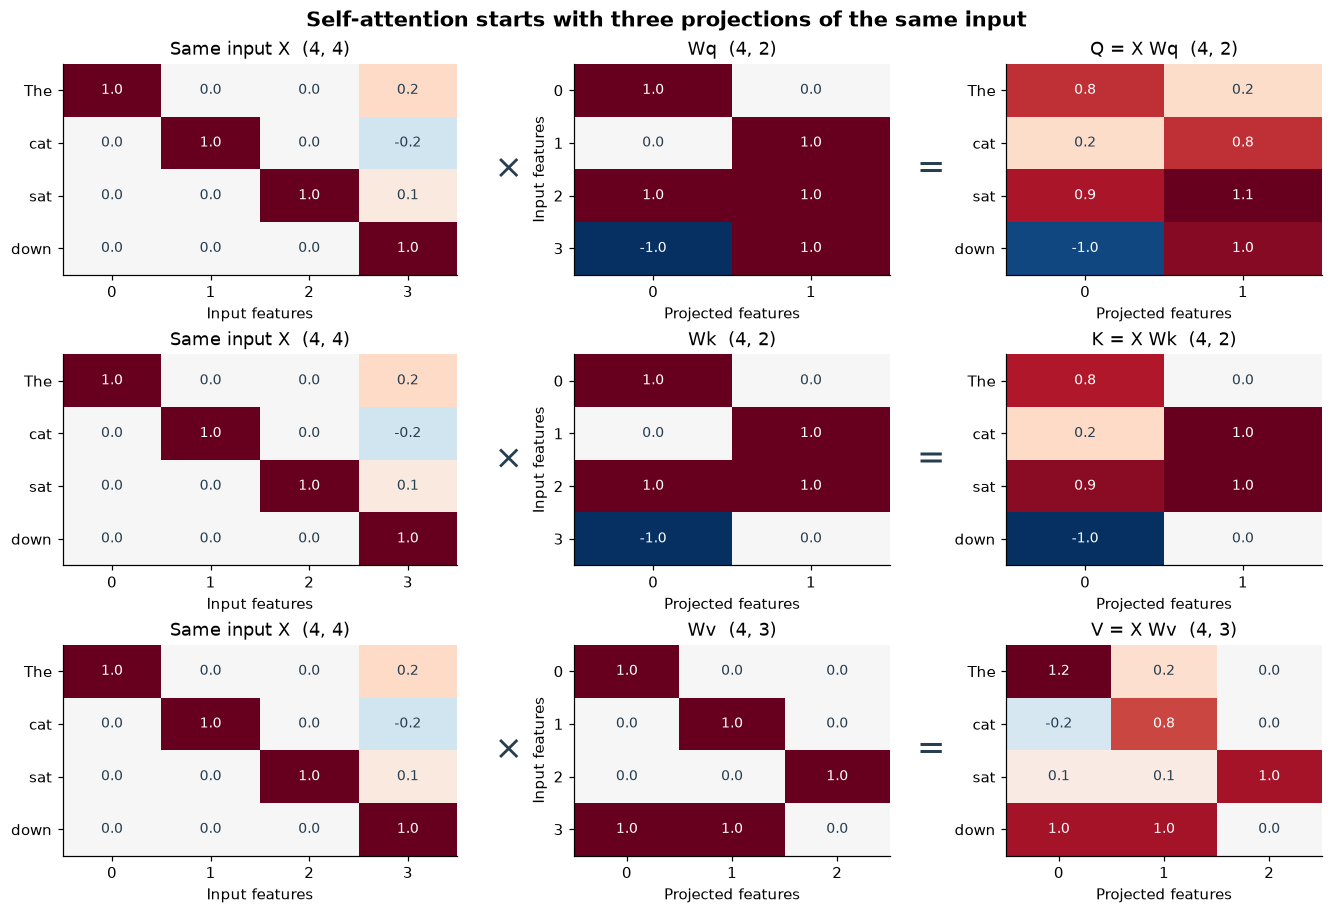

Następnie porównujemy każde query z każdym key za pomocą iloczynu skalarnego i dzielimy wynik przez $\sqrt{d_k}$, gdzie $d_k$ to wymiar wektorów query i key (bez tego wartości rosłyby razem z wymiarem). Wyniki w każdym wierszu zamieniamy softmaksem na wagi sumujące się do 1, a wyjściem jest ważona suma wektorów value:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

Rysunek poniżej pokazuje ten rachunek dla jednego query, dla tokenu „cat”.

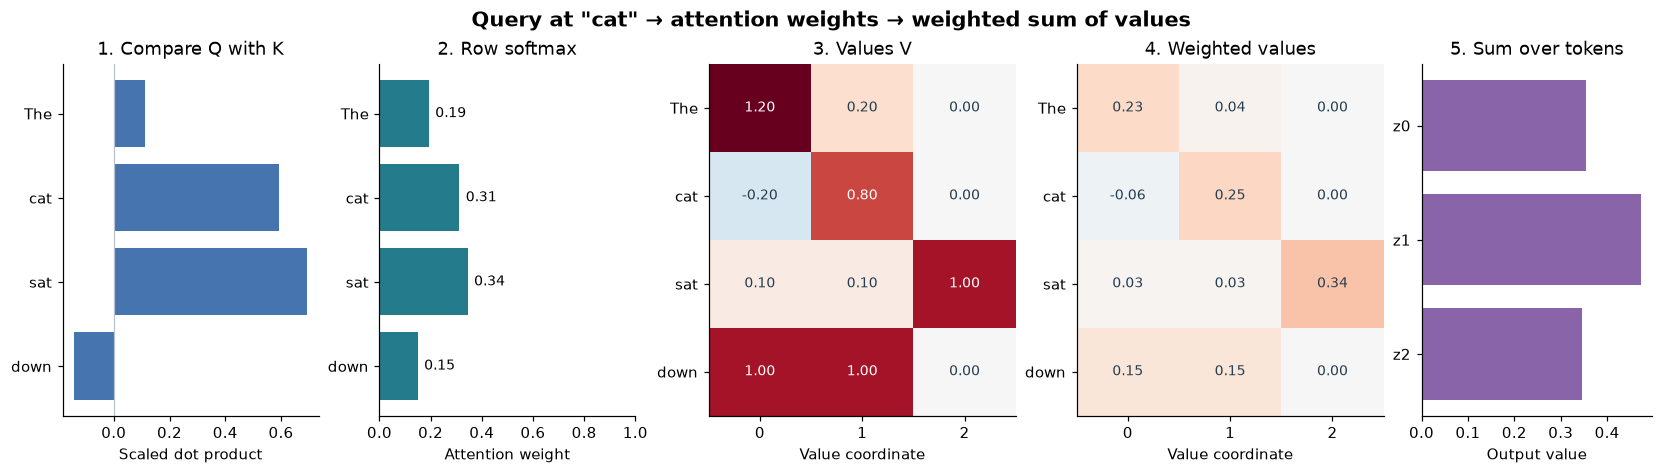

BERT jako enkoder widzi cały tekst, więc każda pozycja może korzystać ze wszystkich pozostałych (**bidirectional attention**). Model generujący tekst (dekoder, np. GPT) przewiduje kolejny token, więc nie może zaglądać w przyszłość. Używa się w nim **maski przyczynowej (causal mask)**: przed softmaksem w miejsca odpowiadające przyszłym pozycjom wpisujemy $-\infty$, dzięki czemu dostają one wagę 0. W praktyce atencję liczy się równolegle w kilku **głowach (heads)** z osobnymi wagami, a ich wyniki się skleja. Blok transformera zawiera też sieć feed-forward działającą osobno na każdej pozycji, połączenia rezydualne (residual connections) i normalizację LayerNorm. Trzy typowe architektury pokazuje rysunek poniżej. Więcej przeczytasz w [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/) i w oryginalnej pracy [Attention Is All You Need](https://arxiv.org/abs/1706.03762).

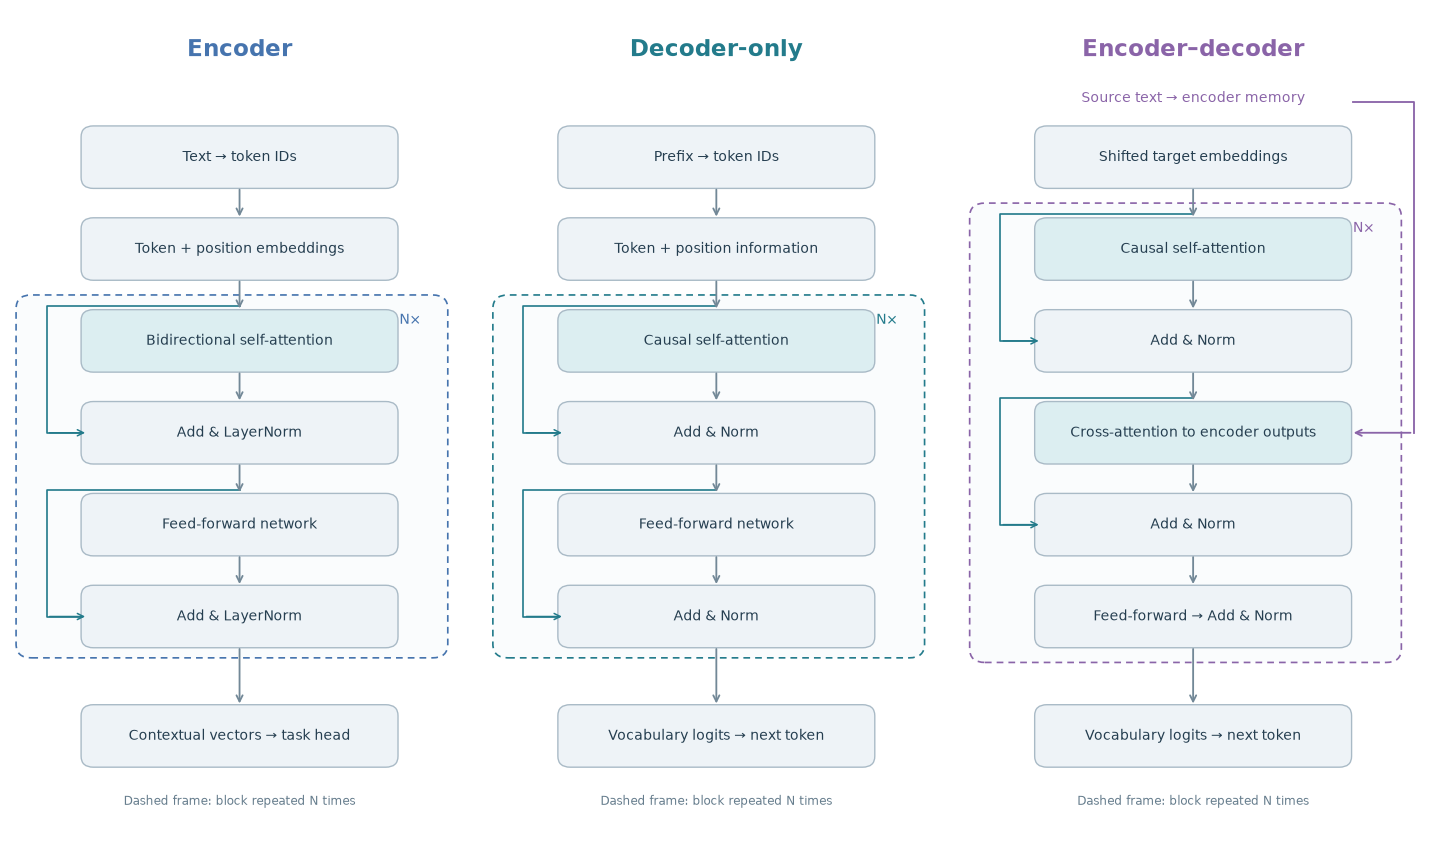

Zaimplementuj funkcję `scaled_attention(q, k, v, allowed=None)`, która zwraca parę `(output, weights)`. Opcjonalna maska `allowed` to macierz logiczna, w której `True` oznacza dozwolone połączenie (wiersz to query, kolumna to key). Zabronione pozycje wypełnij wartością $-\infty$ metodą `masked_fill` przed softmaksem. Jeżeli w którymś wierszu maski nie ma żadnej dozwolonej pozycji, rzuć `ValueError`. Funkcja ma działać także dla tensorów z dodatkowymi wymiarami na początku (np. kilka głów naraz), więc transponuj tylko dwa ostatnie wymiary.

Następnie:
1. Zbuduj dolnotrójkątną maskę przyczynową `causal_allowed` dla 4 tokenów (`torch.tril`) i policz atencję dla macierzy `Q`, `K`, `V` z rysunków bez maski (`full_output`, `full_weights`) i z maską (`causal_output`, `causal_weights`).
2. Sprawdź, co się dzieje po zmianie ostatniego tokenu. Policz atencję z `Q = K = V = X` oraz z `Q = K = V = X_changed`, bez maski (`full_before`, `full_after`) i z maską (`causal_before`, `causal_after`).

In [ ]:
import math

attention_labels = ["The", "cat", "sat", "down"]
attention_input = torch.tensor(
    [
        [1.0, 0.0, 0.0, 0.2],
        [0.0, 1.0, 0.0, -0.2],
        [0.0, 0.0, 1.0, 0.1],
        [0.0, 0.0, 0.0, 1.0],
    ]
)
W_query = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0], [-1.0, 1.0]])
W_key = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0], [-1.0, 0.0]])
W_value = torch.tensor(
    [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [1.0, 1.0, 0.0]]
)
Q, K, V = attention_input @ W_query, attention_input @ W_key, attention_input @ W_value

In [ ]:
def scaled_attention(q, k, v, allowed=None):
    # your_code


X = torch.eye(4)
X_changed = X.clone()
X_changed[-1] = torch.tensor([3.0, -2.0, 1.0, 4.0])

# your_code

In [ ]:
assert full_output.shape == causal_output.shape == (4, 3)
assert torch.allclose(full_weights.sum(-1), torch.ones(4))
assert torch.allclose(causal_weights.sum(-1), torch.ones(4))
assert torch.count_nonzero(causal_weights.triu(1)) == 0
assert torch.allclose(causal_output[0], V[0])
assert torch.allclose(full_output[-1], causal_output[-1])
assert not torch.allclose(full_before[:-1], full_after[:-1])
assert torch.allclose(causal_before[:-1], causal_after[:-1])
# two equal scores give the average of two values
z, _ = scaled_attention(
    torch.zeros(1, 2), torch.zeros(2, 2), torch.tensor([[2.0, 4.0], [6.0, 8.0]])
)
assert torch.allclose(z, torch.tensor([[4.0, 6.0]]))
# several heads at once
heads = torch.randn(2, 4, 3)
assert scaled_attention(heads, heads, heads, causal_allowed)[1].shape == (2, 4, 4)
try:
    scaled_attention(Q, K, V, torch.zeros(4, 4, dtype=torch.bool))
except ValueError:
    pass
else:
    raise AssertionError("A mask with an empty row should be rejected")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, weights, title in zip(
    axes,
    [full_weights, causal_weights],
    ["bidirectional attention", "causal attention"],
):
    ax.imshow(weights.numpy(), vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(4), attention_labels)
    ax.set_yticks(range(4), attention_labels)
    ax.set(title=title, xlabel="key", ylabel="query")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{weights[i, j]:.2f}", ha="center", va="center")
plt.tight_layout()
plt.show()
print(
    "Earlier outputs changed, bidirectional:",
    not torch.allclose(full_before[:-1], full_after[:-1]),
)
print(
    "Earlier outputs changed, causal:",
    not torch.allclose(causal_before[:-1], causal_after[:-1]),
)

### Zadanie dodatkowe 2 (1 punkt)

Model językowy typu dekoder dla danego prefiksu zwraca logity dla każdego tokenu ze słownika, czyli rozkład prawdopodobieństwa następnego tokenu. Tekst generuje się w pętli: wybieramy token, doklejamy go do prefiksu i ponownie liczymy rozkład. Kończymy po osiągnięciu limitu nowych tokenów albo po wygenerowaniu specjalnego tokenu końca tekstu (EOS). Sposób wyboru tokenu to **strategia dekodowania (decoding strategy)**:
- **dekodowanie zachłanne (greedy decoding)** zawsze wybiera token o największym logicie,
- **losowanie (sampling)** losuje token zgodnie z rozkładem. **Temperatura** $\tau$ zmienia kształt rozkładu: $p_i = \frac{\exp(z_i / \tau)}{\sum_j \exp(z_j / \tau)}$. Niska temperatura wyostrza rozkład, wysoka go spłaszcza, a $\tau = 1$ go nie zmienia,
- **top-k** przed losowaniem zostawia tylko $k$ tokenów o największych logitach (pozostałe dostają $-\infty$), dzięki czemu nie wylosujemy bardzo mało prawdopodobnego tokenu.

Użyjemy bardzo małego modelu [Pythia-14m](https://huggingface.co/EleutherAI/pythia-14m), więc wygenerowany tekst nie będzie zbyt sensowny. Pierwsza komórka poniżej pokazuje generowanie gotowym `pipeline("text-generation")`.

Zaimplementuj funkcję `decoding_probs(logits, temperature=1.0, top_k=None)`, która dla jednowymiarowego tensora logitów zwraca rozkład prawdopodobieństwa po zastosowaniu temperatury i opcjonalnie top-k. Dla niedodatniej temperatury albo `top_k` spoza zakresu od 1 do rozmiaru słownika rzuć `ValueError`. Następnie uzupełnij wybór kolejnego tokenu w funkcji `generate_ids`. Przy losowaniu użyj `torch.multinomial` z podanym generatorem liczb losowych `rng`, a w trybie zachłannym wybierz największy logit. Testy sprawdzą, czy Twoja pętla w trybie zachłannym daje dokładnie ten sam wynik co `model.generate`.

Wykres pod testami porównuje prawdopodobieństwa najbardziej prawdopodobnych tokenów przy różnych temperaturach. Legenda podaje też entropię każdego rozkładu, która mierzy, jak bardzo jest on rozproszony.

In [ ]:
from transformers import AutoModelForCausalLM

DECODER_NAME = "EleutherAI/pythia-14m"
decoder_tokenizer = AutoTokenizer.from_pretrained(DECODER_NAME)
decoder = AutoModelForCausalLM.from_pretrained(DECODER_NAME).to(DEVICE).eval()
generator = pipeline(
    "text-generation", model=decoder, tokenizer=decoder_tokenizer, device=DEVICE
)

prompt = "Once upon a time there was"
options = {"max_new_tokens": 24, "pad_token_id": decoder_tokenizer.eos_token_id}
set_seed(SEED)
greedy_text = generator(prompt, do_sample=False, **options)[0]["generated_text"]
sampled_text = generator(prompt, do_sample=True, temperature=0.8, top_k=20, **options)[
    0
]
print("greedy:  ", greedy_text)
print("sampling:", sampled_text["generated_text"])

prefix_ids = decoder_tokenizer("The movie was", return_tensors="pt")["input_ids"].to(
    DEVICE
)
with torch.no_grad():
    next_logits = decoder(input_ids=prefix_ids).logits[0, -1].float().cpu()
print("Next-token logits:", next_logits.shape)

In [ ]:
def decoding_probs(logits, temperature=1.0, top_k=None):
    # your_code


@torch.no_grad()
def generate_ids(
    model,
    input_ids,
    max_new_tokens=24,
    sample=False,
    temperature=1.0,
    top_k=None,
    seed=SEED,
):
    rng = torch.Generator().manual_seed(seed)
    ids = input_ids.clone()
    for _ in range(max_new_tokens):
        logits = model(input_ids=ids).logits[0, -1].cpu()
        if sample:
            chosen = # your_code
        else:
            chosen = # your_code
        ids = torch.cat([ids, torch.tensor([[chosen]], device=ids.device)], dim=1)
        if chosen == model.config.eos_token_id:
            break
    return ids

In [ ]:
assert torch.isclose(decoding_probs(next_logits).sum(), torch.tensor(1.0), atol=1e-4)
assert torch.count_nonzero(decoding_probs(torch.arange(10.0), top_k=3)) == 3
assert (
    decoding_probs(next_logits, 0.5).argmax()
    == decoding_probs(next_logits, 1.5).argmax()
)
for kwargs in [{"temperature": 0}, {"temperature": -1}, {"top_k": 0}]:
    try:
        decoding_probs(next_logits, **kwargs)
    except ValueError:
        pass
    else:
        raise AssertionError(f"decoding_probs(..., **{kwargs}) should fail")

ours = generate_ids(decoder, prefix_ids, max_new_tokens=12)
library = decoder.generate(
    prefix_ids,
    attention_mask=torch.ones_like(prefix_ids),
    max_new_tokens=12,
    do_sample=False,
    pad_token_id=decoder_tokenizer.eos_token_id,
)
assert torch.equal(ours, library)
sampled = generate_ids(decoder, prefix_ids, 12, sample=True, top_k=20, seed=7)
assert torch.equal(
    sampled, generate_ids(decoder, prefix_ids, 12, sample=True, top_k=20, seed=7)
)
print("greedy:  ", decoder_tokenizer.decode(ours[0]))
print("sampling:", decoder_tokenizer.decode(sampled[0]))

candidate_ids = torch.topk(next_logits, 8).indices
fig, ax = plt.subplots(figsize=(11, 4))
for offset, temperature in enumerate([0.5, 1.0, 1.5]):
    probs = decoding_probs(next_logits, temperature)
    entropy = -(probs * probs.clamp_min(1e-30).log()).sum().item()
    ax.bar(
        np.arange(8) + (offset - 1) * 0.25,
        probs[candidate_ids].numpy(),
        width=0.25,
        label=f"T={temperature}, entropy {entropy:.2f}",
    )
ax.set_xticks(
    range(8), [repr(decoder_tokenizer.decode([i])) for i in candidate_ids.tolist()]
)
ax.set(xlabel="next token after 'The movie was'", ylabel="probability")
ax.legend()
plt.tight_layout()
plt.show()